# **Section 2 – Billboard Dataset (Hot 100, 1958–2021)**

## Replicability Check

| Item | Detail |
|---|---|
| Python | 3.13 (virtual environment `.venv`) |
| Packages | `pip install -r requirements.txt` (uses `pandas`, `numpy`, `matplotlib`, `seaborn`, `scipy`, `scikit-learn`, `statsmodels`) |
| Run from | the `notebooks/` folder or the project root |
| Data | Neon tables `billboard_hot100_raw` and `billboard_audio_features_raw` (needs `NEON_DATABASE_URL` in `.env`, see the README) |
| Fallback | without `.env`, the notebook reads `data/billboard_hot100.csv` and `data/billboard_audio_features.csv` |
| Source | TidyTuesday 2021-09-14 (`billboard.csv` and `audio_features.csv`) |
| Not in Git | both files are large (about 46 MB and 10 MB) and are listed in `.gitignore` |

The data is already in the shared Neon database, so with a `.env` you can simply restart the kernel and choose **Run All**.

To load or refresh the data in Neon, run this once from the project root. It downloads the two files into `data/` first if they are missing, uploads them, and verifies the Neon copy matches:

```bash
PYTHONPATH=src python -m billboard_dataset.upload
```

To use the local fallback without Neon, download the two files instead:

```bash
BASE=https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2021/2021-09-14
curl -L $BASE/billboard.csv       -o data/billboard_hot100.csv
curl -L $BASE/audio_features.csv  -o data/billboard_audio_features.csv
```

## **The Research Question**

> **Which characteristics of a song, known when it first enters the chart, help explain how many weeks it stays on the Billboard Hot 100?**

This section follows the Section 2 tasks (2.1–2.8) of the lab and then extends them:

1. **Tasks 2.1–2.8** – load, reshape with `melt()`, clean strings, handle missing values, rebuild chart dates, plot, and reflect.
2. **Feature engineering** – turn the weekly rows into one row per song with useful predictors.
3. **Hypothesis testing** – decide which predictors deserve a place in a linear regression.
4. **Linear regression** – compare a model with all features against one built from the tested features.

### Why this dataset?
The original lab file covers only the year 2000. This file covers more than 60 years of weekly charts (327,895 weekly rows) and can be joined with Spotify audio features, which gives enough columns and rows for feature engineering and regression.

## **Setup**

In [1]:
from pathlib import Path
import ast
import re
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor
from matplotlib import cbook
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

# Works from the project root and from the notebooks/ folder; put src/ on Python's search path.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

from common.database import NeonDatabase  # shared Neon helper (all sections)
from billboard_dataset import read_billboard_csv, read_billboard_neon
from billboard_dataset.config import CHART_TABLE_NAME, AUDIO_TABLE_NAME

### **Task 2.1 – Load and Inspect Billboard Data**

Two tables are loaded from the shared Neon database (or, without a `.env`, from the local CSV files):

- **Chart file** – one row per song per week on the chart.
- **Audio file** – one row per song with its Spotify genre and audio features.

The columns are inspected before anything is changed.

In [2]:
connection_string = NeonDatabase.read_connection_string()

if connection_string:
    db = NeonDatabase(connection_string)
    print("Connected to:", db.test_connection()[:60], "...")
    # Read both tables in their original row order (later steps keep the first of each duplicate)
    chart_raw, audio_raw = read_billboard_neon(db)
    data_source = f"Neon tables '{CHART_TABLE_NAME}' and '{AUDIO_TABLE_NAME}'"
    db.close()
else:
    print("WARNING: NEON_DATABASE_URL is not set in .env - reading the local CSV files instead of Neon.")
    chart_raw, audio_raw = read_billboard_csv()
    data_source = "local CSV files (fallback)"

print("Loaded from:", data_source)

print(f"chart_raw: {chart_raw.shape[0]:,} rows x {chart_raw.shape[1]} columns")
print(f"audio_raw: {audio_raw.shape[0]:,} rows x {audio_raw.shape[1]} columns")
print("\nChart columns:", list(chart_raw.columns))
print("\nAudio columns:", list(audio_raw.columns))
chart_raw.head()

Connected to: PostgreSQL 18.6 (653b019) on aarch64-unknown-linux-gnu, comp ...


Loaded from: Neon tables 'billboard_hot100_raw' and 'billboard_audio_features_raw'
chart_raw: 327,895 rows x 10 columns
audio_raw: 29,503 rows x 22 columns

Chart columns: ['url', 'week_id', 'week_position', 'song', 'performer', 'song_id', 'instance', 'previous_week_position', 'peak_position', 'weeks_on_chart']

Audio columns: ['song_id', 'performer', 'song', 'spotify_genre', 'spotify_track_id', 'spotify_track_preview_url', 'spotify_track_duration_ms', 'spotify_track_explicit', 'spotify_track_album', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'spotify_track_popularity']


,url,week_id,week_position,song,performer,song_id,instance,previous_week_position,peak_position,weeks_on_chart
0,http://www.billboard.com/charts/hot-100/1965-0...,7/17/1965,34,Don't Just Stand There,Patty Duke,Don't Just Stand TherePatty Duke,1,45.0,34,4
1,http://www.billboard.com/charts/hot-100/1965-0...,7/24/1965,22,Don't Just Stand There,Patty Duke,Don't Just Stand TherePatty Duke,1,34.0,22,5
2,http://www.billboard.com/charts/hot-100/1965-0...,7/31/1965,14,Don't Just Stand There,Patty Duke,Don't Just Stand TherePatty Duke,1,22.0,14,6
3,http://www.billboard.com/charts/hot-100/1965-0...,8/7/1965,10,Don't Just Stand There,Patty Duke,Don't Just Stand TherePatty Duke,1,14.0,10,7
4,http://www.billboard.com/charts/hot-100/1965-0...,8/14/1965,8,Don't Just Stand There,Patty Duke,Don't Just Stand TherePatty Duke,1,10.0,8,8


In [3]:
chart_raw.dtypes

url                           str
week_id                       str
week_position               int64
song                          str
performer                     str
song_id                       str
instance                    int64
previous_week_position    float64
peak_position               int64
weeks_on_chart              int64
dtype: object

In [4]:
audio_raw.head(3)

,song_id,performer,song,spotify_genre,spotify_track_id,spotify_track_preview_url,spotify_track_duration_ms,spotify_track_explicit,spotify_track_album,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,spotify_track_popularity
0,-twistin'-White Silver SandsBill Black's Combo,Bill Black's Combo,-twistin'-White Silver Sands,[],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,¿Dònde Està Santa Claus? (Where Is Santa Claus...,Augie Rios,¿Dònde Està Santa Claus? (Where Is Santa Claus?),['novelty'],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,......And Roses And RosesAndy Williams,Andy Williams,......And Roses And Roses,"['adult standards', 'brill building pop', 'eas...",3tvqPPpXyIgKrm4PR9HCf0,https://p.scdn.co/mp3-preview/cef4883cfd1e0e53...,166106.0,False,The Essential Andy Williams,0.154,0.185,5.0,-14.063,1.0,0.0315,0.911,0.000267,0.112,0.15,83.969,4.0,38.0


**What the inspection shows**

- The chart file is already **long**: each row is a song-week with `week_position` (the rank), `weeks_on_chart` (a running count) and `peak_position` (best rank so far).
- `week_id` is stored as text such as `7/17/1965`, so it must be converted to a date.
- `spotify_genre` is a list written as text, for example `['pop', 'post-teen pop']`.
- The audio file has `NA` values for songs without a Spotify match.
- **Identifier columns:** `song_id`, `song`, `performer`. **Measured columns:** `week_position` and the weekly counters.

In [5]:
# Quick quality checks that guide later decisions.
print("Unique songs in chart file:", chart_raw["song_id"].nunique())
print("Unique songs in audio file:", audio_raw["song_id"].nunique())
print("Duplicated song_id in audio file:", audio_raw["song_id"].duplicated().sum())
print("Songs charted more than once (instance > 1):",
      chart_raw.loc[chart_raw["instance"] > 1, "song_id"].nunique())
print("\nMissing values per column (chart):")
print(chart_raw.isna().sum()[lambda s: s > 0])

Unique songs in chart file: 29389
Unique songs in audio file: 29386
Duplicated song_id in audio file: 117
Songs charted more than once (instance > 1): 2102

Missing values per column (chart):
previous_week_position    31954
dtype: int64


**Duplicate check.** A song should appear only once per chart week, and the audio file should have one row per song. Both rules are tested before any analysis, because duplicated rows would be counted twice in every statistic.

In [6]:
chart_rows_loaded, audio_rows_loaded = len(chart_raw), len(audio_raw)

chart_dup_keys = chart_raw.duplicated(subset=["song_id", "week_id"]).sum()
audio_dup_rows = audio_raw.duplicated().sum()
audio_dup_ids = audio_raw["song_id"].duplicated().sum()
print("Chart: exact duplicate rows       :", chart_raw.duplicated().sum())
print("Chart: repeated (song, week) pairs:", chart_dup_keys)
print("Audio: exact duplicate rows       :", audio_dup_rows)
print("Audio: repeated song_id           :", audio_dup_ids)

# Show a few repeated chart pairs side by side (keep=False marks every copy).
chart_raw[chart_raw.duplicated(subset=["song_id", "week_id"], keep=False)] \
    .sort_values(["song_id", "week_id"])[["song", "performer", "week_id", "week_position", "instance", "weeks_on_chart"]].head(6)

Chart: exact duplicate rows       : 0
Chart: repeated (song, week) pairs: 13
Audio: exact duplicate rows       : 24
Audio: repeated song_id           : 117


,song,performer,week_id,week_position,instance,weeks_on_chart
91436,Unchained Melody,The Righteous Brothers,10/13/1990,15,3,22
91437,Unchained Melody,The Righteous Brothers,10/13/1990,30,3,23
91438,Unchained Melody,The Righteous Brothers,10/20/1990,13,3,24
91439,Unchained Melody,The Righteous Brothers,10/20/1990,25,3,25
91440,Unchained Melody,The Righteous Brothers,10/27/1990,15,3,26
91441,Unchained Melody,The Righteous Brothers,10/27/1990,22,3,27


In [7]:
# Keep the first row of every repeated (song, week) pair.
chart_raw = chart_raw.drop_duplicates(subset=["song_id", "week_id"]).reset_index(drop=True)
print(f"Chart rows: {chart_rows_loaded:,} -> {len(chart_raw):,} ({chart_rows_loaded - len(chart_raw)} removed)")

Chart rows: 327,895 -> 327,882 (13 removed)


**Result.**
- **Chart file:** there are no exact duplicate rows, but **13 (song, week) pairs appear twice** (for example *Unchained Melody* by The Righteous Brothers appears twice in the week of 10/13/1990, at ranks 15 and 30, because two versions share one `song_id`). Only the first row of each pair was kept, so 13 of 327,895 rows (0.004 %) were removed.
- **Audio file:** **117 `song_id` values are repeated** (24 of them are exact duplicate rows; the others are the same song listed with slightly different Spotify entries). One row per song is kept, which leaves 29,386 songs.

### **Task 2.2 – Diagnose the Tidiness Problem**

The chart file is already tidy (one observation per row). The lab, however, is about the **wide** layout in which every week is a column (`1st week`, `2nd week`, ...). To practise the same reshaping, a wide table is built first: **one row per song and one column per week on the chart** (first 20 weeks, first run of each song).

Why the wide layout is hard to analyze:

- The week number is stored in the column **names**, not in a column that can be filtered, grouped or plotted.
- Most cells are empty because most songs leave the chart before week 20.
- A single plot of rank against week needs 20 columns to be selected by hand.

| Role | Columns |
|---|---|
| Identifiers (`id_vars`) | `song_id`, `song`, `performer` |
| Weekly measured columns (`value_vars`) | `1st week` ... `20th week` |
| Wanted after reshaping | `Week` (number) and `Rank` |

In [8]:
MAX_WEEKS = 20

def ordinal(n):
    """Return 1 -> '1st', 2 -> '2nd', 11 -> '11th'."""
    suffix = "th" if 10 <= n % 100 <= 20 else {1: "st", 2: "nd", 3: "rd"}.get(n % 10, "th")
    return f"{n}{suffix}"

# First run of each song only (instance == 1) so the week counter is continuous.
first_run = chart_raw[(chart_raw["instance"] == 1) & (chart_raw["weeks_on_chart"] <= MAX_WEEKS)]

billboard_wide = (
    first_run
    .pivot_table(index=["song_id", "song", "performer"],
                 columns="weeks_on_chart", values="week_position", aggfunc="first")
    .rename(columns=lambda n: f"{ordinal(n)} week")
    .reset_index()
)
billboard_wide.columns.name = None
print("Wide table shape:", billboard_wide.shape)
billboard_wide.head()

Wide table shape: (29385, 23)


,song_id,song,performer,1st week,2nd week,3rd week,4th week,5th week,6th week,7th week,8th week,9th week,10th week,11th week,12th week,13th week,14th week,15th week,16th week,17th week,18th week,19th week,20th week
0,"""B"" GirlsYoung And Restless","""B"" Girls",Young And Restless,84.0,78.0,68.0,60.0,58.0,55.0,54.0,57.0,67.0,75.0,77.0,79.0,79.0,83.0,91.0,NaN,NaN,NaN,NaN,NaN
1,"""Cherry Cherry"" from Hot August NightNeil Diamond","""Cherry Cherry"" from Hot August Night",Neil Diamond,84.0,64.0,56.0,49.0,42.0,36.0,35.0,31.0,31.0,51.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,"""Having A Party"" MedleyThe Ovations (Featuring...","""Having A Party"" Medley",The Ovations (Featuring Louis Williams),99.0,95.0,87.0,79.0,73.0,70.0,63.0,56.0,62.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,"""Joy"" Pt. IIsaac Hayes","""Joy"" Pt. I",Isaac Hayes,72.0,62.0,44.0,36.0,33.0,31.0,30.0,30.0,42.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,"""Roots"" MedleyQuincy Jones","""Roots"" Medley",Quincy Jones,87.0,76.0,66.0,64.0,61.0,57.0,83.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### **Task 2.3 – Reshape with `melt()`**

`melt()` moves the 20 week columns into two columns: `Week` (the old column name) and `Rank` (the cell value). The identifier columns stay as they are.

In [9]:
id_vars = ["song_id", "song", "performer"]
week_cols = [c for c in billboard_wide.columns if c.endswith("week")]

billboard_long = billboard_wide.melt(
    id_vars=id_vars, value_vars=week_cols, var_name="Week", value_name="Rank"
)

print("Wide shape:", billboard_wide.shape, "-> Long shape:", billboard_long.shape)
print("Expected rows = songs x week columns =", billboard_wide.shape[0] * len(week_cols))
billboard_long.head(10)

Wide shape: (29385, 23) -> Long shape: (587700, 5)
Expected rows = songs x week columns = 587700


,song_id,song,performer,Week,Rank
0,"""B"" GirlsYoung And Restless","""B"" Girls",Young And Restless,1st week,84.0
1,"""Cherry Cherry"" from Hot August NightNeil Diamond","""Cherry Cherry"" from Hot August Night",Neil Diamond,1st week,84.0
2,"""Having A Party"" MedleyThe Ovations (Featuring...","""Having A Party"" Medley",The Ovations (Featuring Louis Williams),1st week,99.0
3,"""Joy"" Pt. IIsaac Hayes","""Joy"" Pt. I",Isaac Hayes,1st week,72.0
4,"""Roots"" MedleyQuincy Jones","""Roots"" Medley",Quincy Jones,1st week,87.0
5,"""Yep!""Duane Eddy His Twangy Guitar And The Rebels","""Yep!""",Duane Eddy His Twangy Guitar And The Rebels,1st week,99.0
6,#1 Dee JayGoody Goody,#1 Dee Jay,Goody Goody,1st week,88.0
7,#1Nelly,#1,Nelly,1st week,75.0
8,#9 DreamJohn Lennon,#9 Dream,John Lennon,1st week,68.0
9,#BeautifulMariah Carey Featuring Miguel,#Beautiful,Mariah Carey Featuring Miguel,1st week,24.0


### **Task 2.4 – Clean the Week Labels with String Operations**

The `Week` values look like `1st week`. The steps are:

| Step | Method | Purpose |
|---|---|---|
| 1 | `.str.strip()` | remove stray spaces |
| 2 | `.str.lower()` | one consistent case |
| 3 | `.str.replace(" week", "")` | drop the repeated word |
| 4 | `.str.extract(r"(\d+)")` | keep only the digits |

The result is converted to an integer, so weeks can be sorted and used in arithmetic.

In [10]:
week_clean = (
    billboard_long["Week"]
    .str.strip()
    .str.lower()
    .str.replace(" week", "", regex=False)
)
billboard_long["WeekNumber"] = (
    week_clean.str.extract(r"(\d+)", expand=False).astype("int64")
)

print(billboard_long[["Week", "WeekNumber"]].drop_duplicates().head(8))
print("WeekNumber dtype:", billboard_long["WeekNumber"].dtype)
assert billboard_long["WeekNumber"].between(1, MAX_WEEKS).all()

            Week  WeekNumber
0       1st week           1
29385   2nd week           2
58770   3rd week           3
88155   4th week           4
117540  5th week           5
146925  6th week           6
176310  7th week           7
205695  8th week           8
WeekNumber dtype: int64


The same string tools help with the performer names. Songs with a guest artist are written in several ways (`Featuring`, `feat.`, `With`, `x`). A flag is created now because it is used later as a feature. Duo names such as `Hall & Oates` are *not* flagged, because they are one act.

In [11]:
collab_pattern = r"\b(?:featuring|feat\.?|with|duet|x)\b"
billboard_long["performer_clean"] = (
    billboard_long["performer"].str.strip().str.replace(r"\s+", " ", regex=True)
)
billboard_long["is_collab"] = billboard_long["performer_clean"].str.lower().str.contains(
    collab_pattern, regex=True
)
billboard_long[["performer_clean", "is_collab"]].drop_duplicates().query("is_collab").head(5)

,performer_clean,is_collab
2,The Ovations (Featuring Louis Williams),True
9,Mariah Carey Featuring Miguel,True
11,will.i.am Featuring Justin Bieber,True
12,Lil Dicky Featuring Fetty Wap & Rich Homie Quan,True
13,Jay-Z Featuring Beyonce Knowles,True


### **Task 2.5 – Clean Ranking Values and Missing Data**

`Rank` is converted with `pd.to_numeric()` and the missing values are counted.

**Decision:** the empty ranks are **dropped, not filled**. An empty cell means the song was *not on the chart* that week (it had already left). Filling it with a mean or with 0 would invent chart positions that never happened.

In [12]:
billboard_long["Rank"] = pd.to_numeric(billboard_long["Rank"], errors="coerce")

n_missing = billboard_long["Rank"].isna().sum()
print(f"Missing ranks: {n_missing:,} of {len(billboard_long):,} ({n_missing / len(billboard_long):.1%})")

billboard_ranked = billboard_long.dropna(subset=["Rank"]).copy()
billboard_ranked["Rank"] = billboard_ranked["Rank"].astype(int)
print(f"Rows kept: {len(billboard_ranked):,}")
print("Ranks within 1-100:", billboard_ranked["Rank"].between(1, 100).all())

Missing ranks: 297,639 of 587,700 (50.6%)
Rows kept: 290,061
Ranks within 1-100: True


**Missing audio features.** The audio file has a different kind of missing data: songs without a Spotify match have `NA` in *every* audio column at once.

In [13]:
audio = audio_raw.drop_duplicates(subset="song_id").copy()   # one row per song (see the duplicate check in Task 2.1)
audio_cols = ["danceability", "energy", "key", "loudness", "mode", "speechiness",
              "acousticness", "instrumentalness", "liveness", "valence", "tempo",
              "time_signature", "spotify_track_duration_ms", "spotify_track_popularity"]

missing_pct = audio[audio_cols + ["spotify_track_explicit", "spotify_genre"]].isna().mean().mul(100).round(1)
print(missing_pct.to_string())

# Are the audio columns missing together?
print("\nSongs with ALL audio columns missing:", audio[audio_cols].isna().all(axis=1).sum())
print("Songs with SOME (but not all) missing:",
      (audio[audio_cols].isna().any(axis=1) & ~audio[audio_cols].isna().all(axis=1)).sum())

danceability                 17.6
energy                       17.6
key                          17.6
loudness                     17.6
mode                         17.6
speechiness                  17.6
acousticness                 17.6
instrumentalness             17.6
liveness                     17.6
valence                      17.6
tempo                        17.6
time_signature               17.6
spotify_track_duration_ms    17.3
spotify_track_popularity     17.3
spotify_track_explicit       17.3
spotify_genre                 5.4

Songs with ALL audio columns missing: 5094
Songs with SOME (but not all) missing: 71


**Decision for audio features.** The values are missing as a block (no Spotify match), not one at a time. Imputing a mean or median would give hundreds of songs an identical, made-up sound profile. Therefore:

- songs are **kept** for the chart analysis (Tasks 2.6–2.7), and
- for the regression, only songs with audio features (**complete cases**) are used. The notebook later checks whether the missing songs are mostly old, because that affects how far results can be generalised.

Missing genres (`[]`, an empty list) are labelled `Unknown`.

**Impossible values.** Spotify features are measured by an algorithm, so errors look like physically impossible numbers (a tempo of 0 BPM, a time signature of 0). They are errors, not unusual songs, so they are checked against plausible ranges, in the same way as the zero-valued glucose and mileage readings in the other sections.

In [14]:
plausible_ranges = {                       # (lowest, highest) value a real song can have
    "tempo": (30, 250),                    # beats per minute
    "time_signature": (1, 7),
    "spotify_track_duration_ms": (20_000, 1_800_000),   # 20 seconds to 30 minutes
    "loudness": (-60, 5),                  # decibels
    "key": (0, 11),
    **{c: (0, 1) for c in ["danceability", "energy", "speechiness", "acousticness",
                           "instrumentalness", "liveness", "valence"]},
}
rows = []
for col, (low, high) in plausible_ranges.items():
    values = audio[col].dropna()
    rows.append({"feature": col, "allowed_min": low, "allowed_max": high,
                 "observed_min": values.min(), "observed_max": values.max(),
                 "below_min": int((values < low).sum()), "above_max": int((values > high).sum())})
plausibility = pd.DataFrame(rows).set_index("feature")
plausibility["total_invalid"] = plausibility["below_min"] + plausibility["above_max"]
audio_missing_before = int(audio[audio_cols].isna().sum().sum())
plausibility.round(2)

,allowed_min,allowed_max,observed_min,observed_max,below_min,above_max,total_invalid
feature,,,,,,,
tempo,30,250,0.00,241.01,1,0,1
time_signature,1,7,0.00,5.00,2,0,2
spotify_track_duration_ms,20000,1800000,29688.00,3079157.00,0,1,1
loudness,-60,5,-28.03,2.29,0,0,0
key,0,11,0.00,11.00,0,0,0
danceability,0,1,0.00,0.99,0,0,0
energy,0,1,0.00,1.00,0,0,0
speechiness,0,1,0.00,0.95,0,0,0
acousticness,0,1,0.00,0.99,0,0,0


In [15]:
# Recode impossible values as missing (the song stays in the table; the model uses complete cases).
for col, (low, high) in plausible_ranges.items():
    audio.loc[~audio[col].between(low, high) & audio[col].notna(), col] = np.nan
audio_missing_after = int(audio[audio_cols].isna().sum().sum())
print("Impossible values recoded to missing:", audio_missing_after - audio_missing_before)

Impossible values recoded to missing: 4


**Result.** Only **4 impossible values** were found among 29,386 songs: a tempo of 0 BPM (1 song), a time signature of 0 (2 songs) and a track longer than 30 minutes (1 song). They were recoded to missing instead of being imputed, because a value that cannot exist tells nothing about the song. All other features stay inside their plausible ranges (loudness reaches +2.3 dB, which is possible). The effect is small, but without this check a tempo of 0 would have entered the regression as a real measurement.

#### Validation of the cleaning steps

Before and after for the checks above:

In [16]:
validation = pd.DataFrame({
    "before": [chart_rows_loaded, chart_dup_keys, audio_rows_loaded, audio_dup_ids, audio_missing_before],
    "after":  [len(chart_raw), chart_raw.duplicated(subset=["song_id", "week_id"]).sum(),
               len(audio), audio.duplicated(subset="song_id").sum(), audio_missing_after],
}, index=["chart rows", "chart repeated (song, week) pairs", "audio rows",
          "audio repeated song_id", "audio missing numeric cells"])
assert validation.loc["chart repeated (song, week) pairs", "after"] == 0
assert validation.loc["audio repeated song_id", "after"] == 0
assert billboard_ranked["Rank"].between(1, 100).all()
validation

,before,after
chart rows,327895,327882
"chart repeated (song, week) pairs",13,0
audio rows,29503,29386
audio repeated song_id,117,0
audio missing numeric cells,72128,72132


### **Task 2.6 – Date Enhancement**

The chart date of each weekly observation is rebuilt from the song's debut date:

$$
\text{chart date} = \text{debut date} + (\text{week number} - 1) \times 7\ \text{days}
$$

The `-1` matters: week 1 is the debut week itself, so it adds zero days. Without it every date would be one week late (an off-by-one error).

The rebuilt dates are compared with the real chart dates in the file.

In [17]:
chart = chart_raw.copy()
chart["chart_date"] = pd.to_datetime(chart["week_id"], format="%m/%d/%Y")

# Debut = the first week a song appears in the file (21 songs already show a week counter above 1 on that row).
debut = (
    chart.sort_values("chart_date")
    .groupby("song_id", as_index=False)
    .first()[["song_id", "chart_date", "week_position"]]
    .rename(columns={"chart_date": "debut_date", "week_position": "debut_position"})
)

dated = billboard_ranked.merge(debut[["song_id", "debut_date"]], on="song_id", how="left")
dated["chart_date_calc"] = dated["debut_date"] + pd.to_timedelta((dated["WeekNumber"] - 1) * 7, unit="D")

# Compare with the real date for the same song and week count.
real = first_run[["song_id", "weeks_on_chart"]].assign(
    chart_date_real=pd.to_datetime(first_run["week_id"], format="%m/%d/%Y")
)
dated = dated.merge(real, left_on=["song_id", "WeekNumber"], right_on=["song_id", "weeks_on_chart"], how="left")

mismatch = (dated["chart_date_calc"] != dated["chart_date_real"]).sum()
print(f"Rows checked: {len(dated):,}")
print(f"Rows where calculated date differs from the real date: {mismatch:,} ({mismatch / len(dated):.2%})")
print("Date range:", dated["chart_date_calc"].min().date(), "->", dated["chart_date_calc"].max().date())

Rows checked: 290,061
Rows where calculated date differs from the real date: 173 (0.06%)
Date range: 1958-08-02 -> 2021-05-29


In [18]:
# Look at the differences: are they off by one week, or gaps in the chart history?
diff_days = (dated["chart_date_real"] - dated["chart_date_calc"]).dt.days
print(diff_days[diff_days != 0].value_counts().head(6))

-49    46
-21    29
-7     23
-28    23
-35    15
-42    14
Name: count, dtype: int64


**Result.** The calculated date matches the real chart date for 290,061 − 173 rows; only **173 rows (0.06 %)** differ. All differences are exact multiples of 7 days and negative (the real date is *earlier* than the calculated one). They come from 21 songs whose first row in the file already has a week counter above 1 (they entered the chart before the file starts counting them), so the "debut date" used in the formula is really week 2, 3, ... of their run. The `- 1` in the formula is therefore correct; the remaining differences are a data-quality limitation, not an off-by-one error. The `debut_date` of those 21 songs is only approximate.

### **Task 2.7 – Billboard Visualization and Trend Analysis**

Two plots:

1. **Rank trajectories** of a few songs. A smaller number is a better rank, so the y-axis is inverted: the best position is at the top.
2. **Distribution of peak position by decade.**

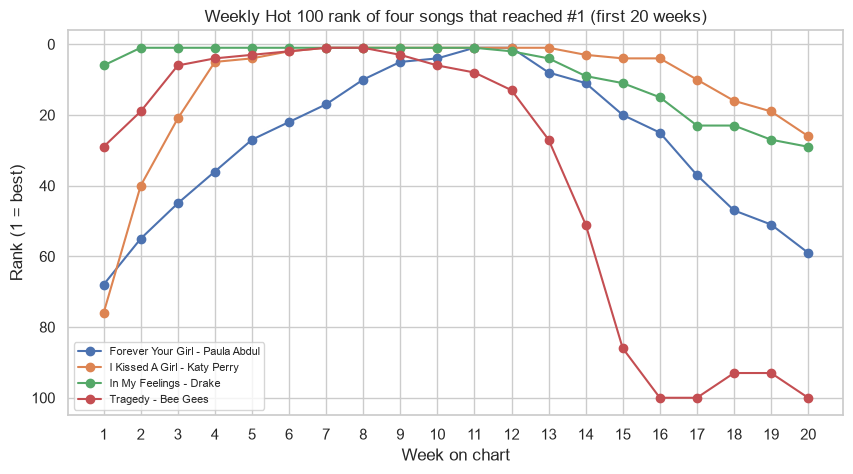

In [19]:
# Pick the three songs that stayed longest in their first 20 weeks and reached #1 (clear, readable lines).
top_songs = (
    billboard_ranked.groupby("song_id")["Rank"].agg(["min", "count"])
    .query("`min` == 1 and `count` == @MAX_WEEKS").sample(4, random_state=RANDOM_STATE).index
)
fig, ax = plt.subplots(figsize=(10, 5))
for sid, grp in billboard_ranked[billboard_ranked["song_id"].isin(top_songs)].groupby("song_id"):
    label = f"{grp['song'].iloc[0][:30]} - {grp['performer'].iloc[0][:20]}"
    ax.plot(grp["WeekNumber"], grp["Rank"], marker="o", label=label)
ax.invert_yaxis()
ax.set_xlabel("Week on chart")
ax.set_ylabel("Rank (1 = best)")
ax.set_title("Weekly Hot 100 rank of four songs that reached #1 (first 20 weeks)")
ax.set_xticks(range(1, MAX_WEEKS + 1, 1))
ax.legend(fontsize=8)
plt.show()

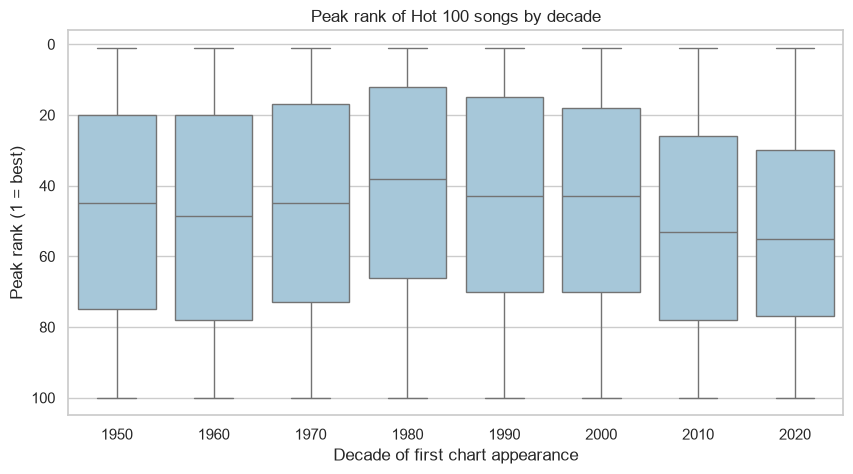

In [20]:
peaks = chart_raw.groupby("song_id").agg(peak=("week_position", "min"), first_year=("week_id", lambda s: pd.to_datetime(s, format="%m/%d/%Y").min().year))
peaks["decade"] = (peaks["first_year"] // 10 * 10).astype(int)

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=peaks, x="decade", y="peak", ax=ax, color="#9ecae1")
ax.invert_yaxis()
ax.set_xlabel("Decade of first chart appearance")
ax.set_ylabel("Peak rank (1 = best)")
ax.set_title("Peak rank of Hot 100 songs by decade")
plt.show()

**What the plots show**

- **Trajectories:** the four songs rise to #1 at different speeds (Drake and Katy Perry jump in within one to four weeks; Paula Abdul climbs for 11 weeks) and then decline. `Tragedy` falls out of the top 50 by week 15 and sits at rank 100 for weeks 16–20, which is typical of a song that peaks quickly and fades.
- **Peak rank by decade:** the typical (median) peak is best for songs that debuted in the 1980s (about rank 38) and gets worse in the 2010s and 2020s (about rank 53–55). The 2020s box is based on only about a year and a half of data, so it should not be over-interpreted.

### **Task 2.8 – Billboard Reflection**

**1. Why was `melt()` appropriate for the weekly ranking columns?**
The week number was stored in 20 column names (`1st week` ... `20th week`) and the cell values were ranks. `melt()` moves the names into a `Week` column and the values into a `Rank` column, so there is one row per song per week. That layout can be filtered, grouped and plotted directly.

**2. Which string operations did you use and what did each accomplish?**
- `.str.strip()` removed stray spaces.
- `.str.lower()` made the text a single case.
- `.str.replace(" week", "")` removed the repeated word.
- `.str.extract(r"(\d+)")` kept only the digits of the week number.
- `.str.contains()` with a regular expression flagged guest artists in the performer name.

**3. Why should the cleaned week number be numeric?**
Text sorts alphabetically (`"10th"` comes before `"2nd"`), cannot be used in arithmetic, and plots in the wrong order. As an integer it sorts correctly and can be used to calculate dates (`debut date + (week − 1) × 7 days`).

**4. How did you handle missing ranking values, and why?**
There were 297,639 empty ranks out of 587,700 cells (50.6 %). I dropped them because an empty cell means the song was not on the chart that week. Filling them would invent chart positions. For the Spotify audio features, the missing values come as a block (5,094 songs have no Spotify match), so I kept those songs for the chart analysis but used only complete cases for the regression.

**5. What trend did your visualization reveal?**
Songs usually climb for several weeks, peak, and then fall; how fast differs a lot between songs. Across decades, the typical peak rank was best in the 1980s and worse in the 2010s, probably because more songs now enter the chart and leave quickly.

**6. What data-quality issue could lead to an incorrect ranking trend?**
- Rank 1 is the *best*, so averaging or plotting ranks without inverting the axis can reverse the reading.
- Filling missing ranks with 0 or the mean would create false positions.
- Songs that re-enter the chart (`instance` > 1) and the 21 songs whose first row already has a week counter above 1 make the "week number" and the debut date unreliable if they are not checked.
- The 2020s are an incomplete decade.

**7. How is this Billboard transformation more complex than the PEW transformation?**
PEW only needed one `melt()` because the column names were already clean income ranges. Here the column names also had to be cleaned with string methods and converted to numbers, the cells contained missing values that had a meaning (not on the chart), and the weeks could be converted to dates. The data also had to be joined with a second file and rebuilt into a song-level table.

---
# **Part B – Feature Engineering and Hypothesis Testing**

The regression needs **one row per song**. The weekly rows are collapsed into a song-level table, and only information that is known **at debut** is used as a predictor, so the model does not use the future to explain the future.

**Target:** `weeks_on_chart` (total weeks on the chart). It is a count with a long right tail, so its logarithm `log_weeks = log(weeks_on_chart)` is used.

In [21]:
songs = (
    chart.groupby("song_id")
    .agg(song=("song", "first"), performer=("performer", "first"),
         weeks_on_chart=("weeks_on_chart", "max"),
         peak_position=("week_position", "min"),
         n_instances=("instance", "max"))
    .reset_index()
    .merge(debut, on="song_id", how="left")
)
songs["debut_year"] = songs["debut_date"].dt.year
songs["debut_decade"] = (songs["debut_year"] // 10 * 10)
songs["debut_month"] = songs["debut_date"].dt.month
songs["is_collab"] = songs["performer"].str.lower().str.contains(collab_pattern, regex=True)
songs["log_weeks"] = np.log(songs["weeks_on_chart"])

# Audio features and genre.
audio["explicit"] = audio["spotify_track_explicit"].map({True: 1, False: 0, "True": 1, "False": 0})
audio["duration_min"] = audio["spotify_track_duration_ms"] / 60_000
audio["genres"] = audio["spotify_genre"].fillna("[]").apply(ast.literal_eval)

def main_genre(genres):
    """Group the long Spotify genre list into a few broad families."""
    text = " ".join(genres).lower()
    if not text:
        return "Unknown"
    for family, keywords in [("Hip hop / rap", ["hip hop", "rap"]),
                             ("Country", ["country"]),
                             ("R&B / soul", ["r&b", "soul", "motown", "funk"]),
                             ("Rock", ["rock", "metal", "grunge"]),
                             ("Dance / electronic", ["dance", "edm", "disco", "house", "electro"]),
                             ("Pop", ["pop"])]:
        if any(k in text for k in keywords):
            return family
    return "Other"

audio["genre_main"] = audio["genres"].apply(main_genre)
audio["n_genres"] = audio["genres"].apply(len)

songs = songs.merge(audio[["song_id", "genre_main", "n_genres", "explicit", "duration_min"] + audio_cols[:-2]
                          + ["spotify_track_popularity"]].drop(columns=["time_signature"], errors="ignore"),
                    on="song_id", how="left")
songs["has_audio"] = songs["danceability"].notna()
songs["genre_main"] = songs["genre_main"].fillna("Unknown")

print("Songs table:", songs.shape)
songs.head()

Songs table: (29389, 30)


,song_id,song,performer,weeks_on_chart,peak_position,n_instances,debut_date,debut_position,debut_year,debut_decade,debut_month,is_collab,log_weeks,genre_main,n_genres,explicit,duration_min,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,spotify_track_popularity,has_audio
0,"""B"" GirlsYoung And Restless","""B"" Girls",Young And Restless,15,54,1,1990-05-05,84,1990,1990,5,False,2.708050,Unknown,0.0,0.0,4.035100,0.615,0.497,7.0,-11.913,1.0,0.439,0.0160,0.000000,0.312,0.769,193.762,20.0,True
1,"""Cherry Cherry"" from Hot August NightNeil Diamond","""Cherry Cherry"" from Hot August Night",Neil Diamond,10,31,1,1973-03-17,84,1973,1970,3,False,2.302585,Rock,8.0,0.0,7.388667,0.340,0.948,9.0,-5.061,1.0,0.137,0.0941,0.000907,0.867,0.604,172.349,16.0,True
2,"""Having A Party"" MedleyThe Ovations (Featuring...","""Having A Party"" Medley",The Ovations (Featuring Louis Williams),9,56,1,1973-10-13,99,1973,1970,10,True,2.197225,R&B / soul,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
3,"""Joy"" Pt. IIsaac Hayes","""Joy"" Pt. I",Isaac Hayes,9,30,1,1973-12-22,72,1973,1970,12,False,2.197225,R&B / soul,9.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
4,"""Roots"" MedleyQuincy Jones","""Roots"" Medley",Quincy Jones,7,57,1,1977-03-05,87,1977,1970,3,False,1.945910,R&B / soul,7.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False


**Engineered features**

| Feature | Meaning | Known at debut? |
|---|---|---|
| `debut_position` | rank in the first week | yes |
| `debut_year`, `debut_decade`, `debut_month` | when the song entered | yes |
| `is_collab` | performer name contains featuring / feat. / with / x (guest artist) | yes |
| `explicit`, `duration_min`, `genre_main` | content flags from Spotify | yes |
| audio features | danceability, energy, loudness, tempo, valence, ... | yes |
| `n_instances` | re-entries on the chart | **no** (uses later weeks) – excluded |
| `peak_position` | best rank ever | **no** – excluded (leakage) |
| `spotify_track_popularity` | Spotify score measured today | **no** – reflects later success, excluded |

**Are songs with missing audio features different?** If they are mostly old, the regression result applies to the Spotify-era mix of songs, and that must be stated.

          debut_year                  weeks_on_chart              
               count     mean  median          count   mean median
has_audio                                                         
False           5165  1980.41  1975.0           5165   8.48    7.0
True           24224  1987.64  1985.0          24224  11.73   10.0


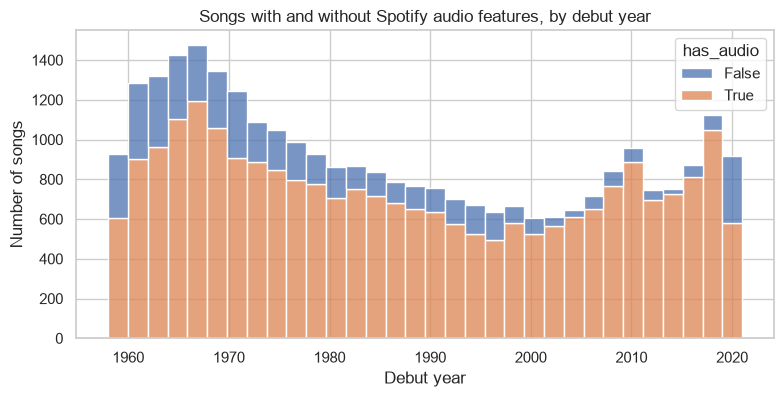

In [22]:
print(songs.groupby("has_audio")[["debut_year", "weeks_on_chart"]].agg(["count", "mean", "median"]).round(2))

fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=songs, x="debut_year", hue="has_audio", multiple="stack", bins=32, ax=ax)
ax.set_xlabel("Debut year")
ax.set_ylabel("Number of songs")
ax.set_title("Songs with and without Spotify audio features, by debut year")
plt.show()

Songs used for modelling: 24,218 of 29,389


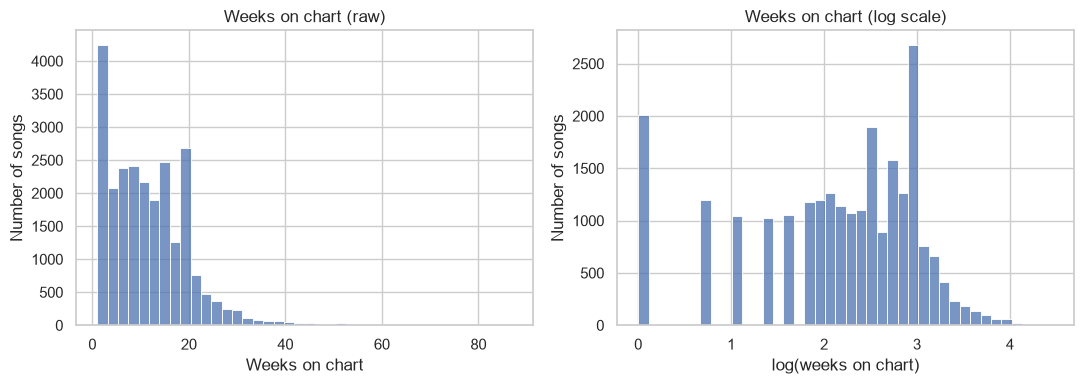

Skewness raw: 1.26 | log: -0.85


In [23]:
model_df = songs[songs["has_audio"]].copy()
numeric_features = ["debut_position", "debut_year", "debut_month", "duration_min", "danceability",
                    "energy", "loudness", "speechiness", "acousticness", "instrumentalness",
                    "liveness", "valence", "tempo", "mode", "key", "n_genres"]
model_df = model_df.dropna(subset=numeric_features + ["explicit", "log_weeks"]).copy()
model_df["debut_decade"] = model_df["debut_decade"].astype(int)
print(f"Songs used for modelling: {len(model_df):,} of {len(songs):,}")

# Target distribution: raw vs log.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(model_df["weeks_on_chart"], bins=40, ax=axes[0])
axes[0].set(title="Weeks on chart (raw)", xlabel="Weeks on chart", ylabel="Number of songs")
sns.histplot(model_df["log_weeks"], bins=40, ax=axes[1])
axes[1].set(title="Weeks on chart (log scale)", xlabel="log(weeks on chart)", ylabel="Number of songs")
plt.tight_layout()
plt.show()
print("Skewness raw:", round(stats.skew(model_df["weeks_on_chart"]), 2),
      "| log:", round(stats.skew(model_df["log_weeks"]), 2))

## **Correlation Between Features**

Before testing features one at a time, a heatmap shows which features move together. Strongly related features (for example `energy` and `loudness`) carry overlapping information and can make regression coefficients unstable.

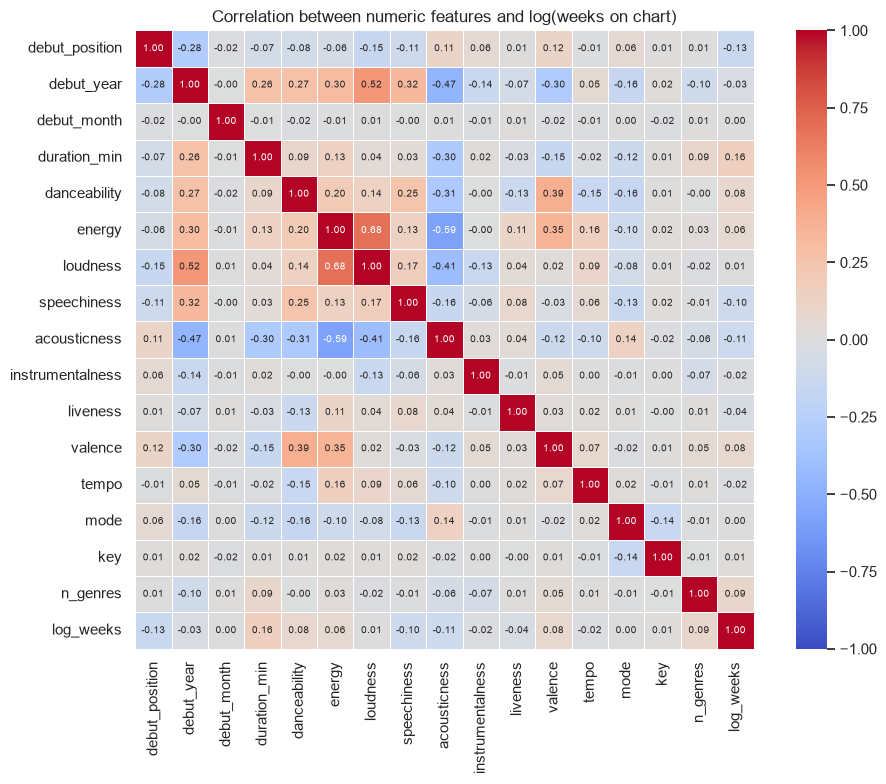

In [24]:
corr = model_df[numeric_features + ["log_weeks"]].corr()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True,
            linewidths=0.5, annot_kws={"size": 7}, ax=ax)
ax.set(title="Correlation between numeric features and log(weeks on chart)")
plt.tight_layout()
plt.show()

**Reading the heatmap.** Most features are only weakly related to each other. The notable pairs are `energy` and `loudness` (r ≈ +0.68) and `energy` and `acousticness` (r ≈ −0.59): loud songs are energetic and acoustic songs are quiet. This overlap is the reason a VIF check is run before the regression. None of the audio features has a strong relationship with `log_weeks` (|r| < 0.17), which already suggests that the final model cannot be very accurate.

## **Outlier Detection**

An outlier is a value far from the rest. Outliers can distort means, correlations and regression coefficients, but detecting one does **not** mean it must be removed. Three views are compared on the main numeric variables:

| Rule | Flags a value when | Based on |
|---|---|---|
| Box plot | it is drawn beyond the whiskers (1.5 × IQR from the box) | quartiles (visual) |
| IQR rule | it is below Q1 − 1.5·IQR or above Q3 + 1.5·IQR | quartiles (robust) |
| Z-score | the absolute z is above 3, with z = (x − mean) / standard deviation | mean and SD (pulled by outliers) |

In [25]:
outlier_features = ["weeks_on_chart", "log_weeks", "duration_min", "tempo", "loudness", "speechiness", "debut_position"]
data = model_df[outlier_features]

z_mask = ((data - data.mean()) / data.std(ddof=0)).abs() > 3
q1, q3 = data.quantile(0.25), data.quantile(0.75)
iqr = q3 - q1
iqr_mask = (data < q1 - 1.5 * iqr) | (data > q3 + 1.5 * iqr)
box_counts = pd.Series({f: len(cbook.boxplot_stats(data[f], whis=1.5)[0]["fliers"]) for f in outlier_features})

outlier_summary = pd.DataFrame({
    "box_plot": box_counts, "z_score": z_mask.sum(), "iqr_rule": iqr_mask.sum(),
    "flagged_by_both": (z_mask & iqr_mask).sum(), "skewness": data.skew().round(2),
})
outlier_summary["iqr_%"] = (outlier_summary["iqr_rule"] / len(model_df) * 100).round(2)
outlier_summary

,box_plot,z_score,iqr_rule,flagged_by_both,skewness,iqr_%
weeks_on_chart,375,306,375,306,1.26,1.55
log_weeks,0,0,0,0,-0.85,0.00
duration_min,561,280,561,280,2.13,2.32
tempo,277,69,277,69,0.52,1.14
loudness,180,129,180,129,-0.65,0.74
speechiness,3344,717,3344,717,3.17,13.81
debut_position,1441,641,1441,641,-1.74,5.95


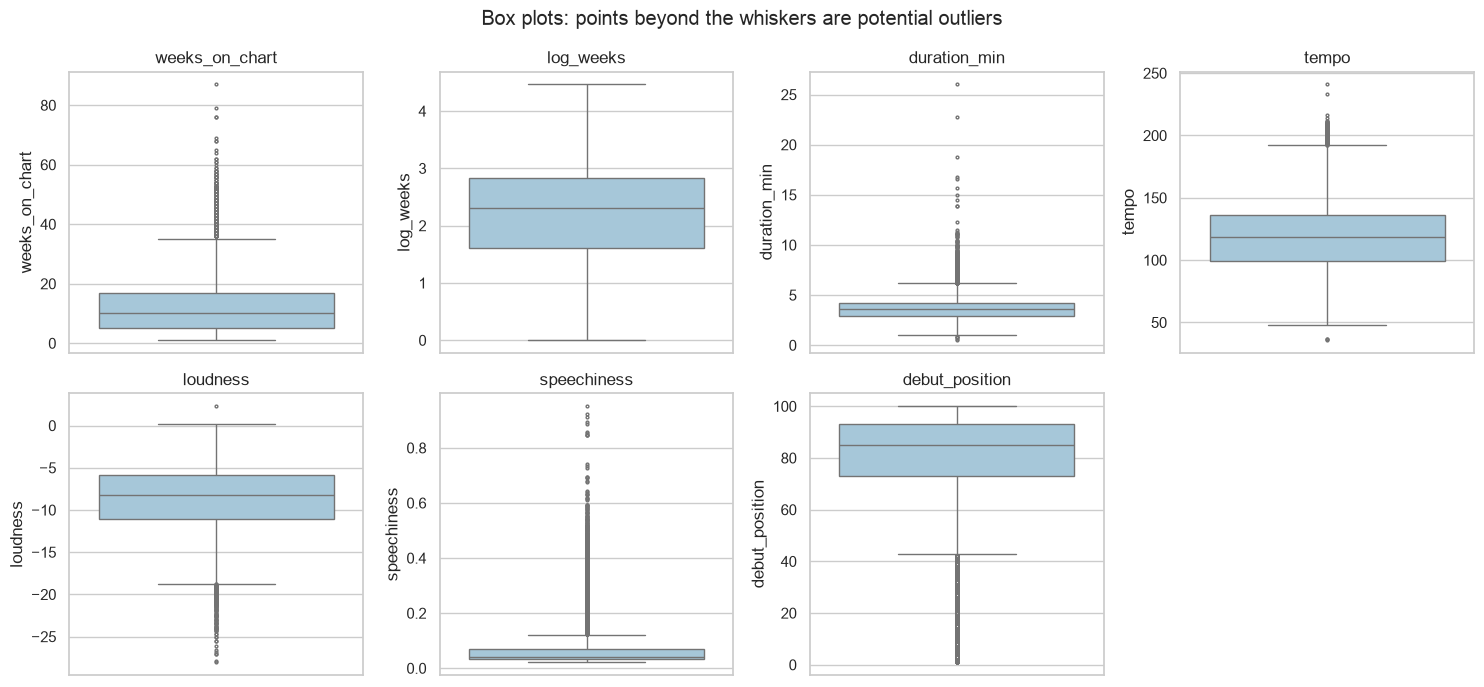

In [26]:
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for ax, col in zip(axes.flat, outlier_features):
    sns.boxplot(y=model_df[col], ax=ax, color="#9ecae1", fliersize=2)
    ax.set(title=col, ylabel=col)
axes.flat[-1].set_visible(False)
fig.suptitle("Box plots: points beyond the whiskers are potential outliers")
plt.tight_layout()
plt.show()

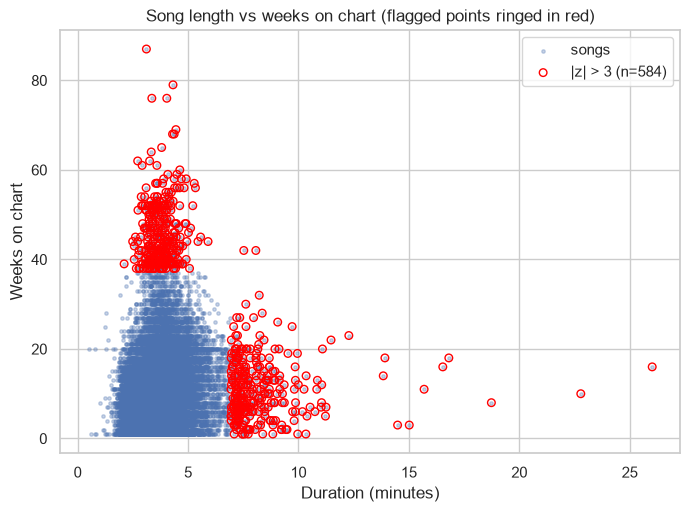

In [27]:
fig, ax = plt.subplots(figsize=(8, 5.5))
flag = z_mask["duration_min"] | z_mask["weeks_on_chart"]
ax.scatter(model_df["duration_min"], model_df["weeks_on_chart"], s=6, alpha=0.3, label="songs")
ax.scatter(model_df.loc[flag, "duration_min"], model_df.loc[flag, "weeks_on_chart"], s=30,
           facecolor="none", edgecolor="red", label=f"|z| > 3 (n={int(flag.sum())})")
ax.set(title="Song length vs weeks on chart (flagged points ringed in red)",
       xlabel="Duration (minutes)", ylabel="Weeks on chart")
ax.legend()
plt.show()

**Who are the outliers?** Before removing anything, look at which songs the rules flag.

In [28]:
long_runs = model_df[iqr_mask["weeks_on_chart"]]
print(f"Songs flagged on weeks_on_chart by the IQR rule: {len(long_runs):,} "
      f"(upper bound = {q3['weeks_on_chart'] + 1.5 * iqr['weeks_on_chart']:.1f} weeks)")
print("\nShare of flagged songs by decade (%):")
print((long_runs["debut_decade"].value_counts(normalize=True).sort_index() * 100).round(1).to_string())
long_runs.nlargest(5, "weeks_on_chart")[["song", "performer", "weeks_on_chart", "peak_position", "debut_year"]]

Songs flagged on weeks_on_chart by the IQR rule: 375 (upper bound = 35.0 weeks)

Share of flagged songs by decade (%):
debut_decade
1950     0.3
1960     0.8
1970     0.8
1980     1.6
1990    15.7
2000    28.8
2010    50.7
2020     1.3


,song,performer,weeks_on_chart,peak_position,debut_year
19483,Radioactive,Imagine Dragons,87,3,2012
20477,Sail,AWOLNATION,79,17,2011
2874,Blinding Lights,The Weeknd,76,1,2019
12105,I'm Yours,Jason Mraz,76,6,2008
10190,How Do I Live,LeAnn Rimes,69,2,1997


In [29]:
mid = model_df["duration_min"].median()
short_songs = model_df[iqr_mask["duration_min"] & (model_df["duration_min"] < mid)]
long_songs = model_df[iqr_mask["duration_min"] & (model_df["duration_min"] > mid)]
print(f"Unusually short songs: {len(short_songs)} | unusually long songs: {len(long_songs)}")
long_songs.nlargest(3, "duration_min")[["song", "performer", "duration_min", "weeks_on_chart"]]

Unusually short songs: 5 | unusually long songs: 556


,song,performer,duration_min,weeks_on_chart
26131,Tubular Bells,Mike Oldfield,26.018883,16
1815,Autobahn,Kraftwerk,22.784883,10
3487,By The Time I Get To Phoenix,Isaac Hayes,18.735883,8


**Reading the outlier results**

- **`log_weeks` has no outliers** on any rule, while the raw `weeks_on_chart` has 375 (IQR) / 306 (Z-score). The skew was a scale problem that the log transform removes, which is another reason for using the log target.
- **Z-score vs IQR:** the IQR rule flags more values than the Z-score for every variable (for example `speechiness`: 3,344 vs 717). The reason is that the two methods use different centres and spreads: the SD is inflated by the extreme values themselves, so |z| > 3 is a wider fence. `speechiness` is highly right-skewed (skew 3.2), so 13.8 % of songs lie beyond the IQR fence. Those are rap and spoken-word songs, which are a real group, not errors.
- **Long chart runs are legitimate hits.** The 375 songs above 35 weeks include *Radioactive* (87 weeks), *Blinding Lights* (76) and *How Do I Live* (69). About 96 % of them debuted in 1990 or later, because the chart rules changed and long runs became possible. Deleting them would remove the very songs the research question is about, so they are **kept** in the main model.
- **Duration:** 556 songs are unusually long (over about 7 minutes; the longest is *Tubular Bells* at 26 minutes) and only 5 unusually short. These are rare but real tracks, so they were kept; the only values removed as errors were the 4 impossible ones in Task 2.5.
- **Scatter plot:** the long-running songs cluster at 3–5 minutes, while songs longer than 7 minutes almost never stay on the chart for 20+ weeks.

## **Hypothesis Tests**

With more than 20,000 songs, almost any correlation is "statistically significant", so **two** criteria are used for keeping a feature:

1. **Statistical:** the p-value stays below 0.05 after a Holm correction for running many tests at once.
2. **Practical:** the effect is not tiny (|r| ≥ 0.05 for a numeric feature, η² ≥ 0.01 for a group variable).

### Step 1 – Check assumptions

Shapiro-Wilk on log_weeks (sample of 5,000): W = 0.9153, p = 1.88e-46
Levene test (explicit vs not): statistic = 1390.78, p = 4.92e-296


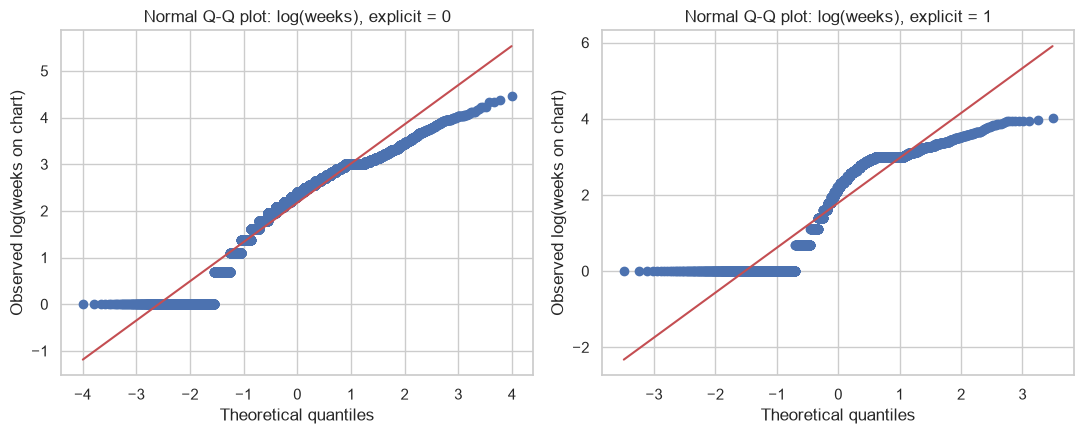

In [30]:
sample = model_df["log_weeks"].sample(5000, random_state=RANDOM_STATE)
w, p = stats.shapiro(sample)
print(f"Shapiro-Wilk on log_weeks (sample of 5,000): W = {w:.4f}, p = {p:.2e}")
lev = stats.levene(*[g["log_weeks"].values for _, g in model_df.groupby("explicit")])
print(f"Levene test (explicit vs not): statistic = {lev.statistic:.2f}, p = {lev.pvalue:.2e}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (label, grp) in zip(axes, model_df.groupby("explicit")):
    stats.probplot(grp["log_weeks"], dist="norm", plot=ax)
    ax.set(title=f"Normal Q-Q plot: log(weeks), explicit = {int(label)}",
           xlabel="Theoretical quantiles", ylabel="Observed log(weeks on chart)")
plt.tight_layout()
plt.show()

**Reading the Q-Q plots.** Neither group follows the straight line. `log_weeks` has a **floor at 0**, because every song that charted for only one week has log(1) = 0, which creates the flat stretch on the left; the right end is cut off because there is a limit to how long songs stay. That agrees with the Shapiro–Wilk result (p < 0.001). With more than 24,000 songs the t-test and ANOVA are still reasonably robust, and the rank-based tests below are used as a cross-check.

Normality is only approximate, but with thousands of observations the t-test, ANOVA and correlation are robust to mild departures. Spearman correlation and Kruskal–Wallis are added as checks that do not assume normality. Welch's t-test is used because it does not assume equal variances.

### Step 2 – Numeric features: correlation with `log_weeks`

- **H₀:** the feature has no linear relationship with `log_weeks` (ρ = 0).
- **H₁:** ρ ≠ 0.

In [31]:
rows = []
for col in numeric_features:
    r, p_r = stats.pearsonr(model_df[col], model_df["log_weeks"])
    rho, p_s = stats.spearmanr(model_df[col], model_df["log_weeks"])
    rows.append({"feature": col, "pearson_r": r, "p_pearson": p_r, "spearman_rho": rho, "p_spearman": p_s})
corr_tbl = pd.DataFrame(rows)
corr_tbl["p_holm"] = multipletests(corr_tbl["p_pearson"], method="holm")[1]
corr_tbl["keep"] = (corr_tbl["p_holm"] < 0.05) & (corr_tbl["pearson_r"].abs() >= 0.05)
corr_tbl = corr_tbl.reindex(corr_tbl["pearson_r"].abs().sort_values(ascending=False).index).reset_index(drop=True)
corr_tbl.round(4)

,feature,pearson_r,p_pearson,spearman_rho,p_spearman,p_holm,keep
0,duration_min,0.1608,0.0000,0.2394,0.0000,0.0000,True
1,debut_position,-0.1345,0.0000,-0.2019,0.0000,0.0000,True
2,acousticness,-0.1150,0.0000,-0.1471,0.0000,0.0000,True
3,speechiness,-0.1039,0.0000,-0.0380,0.0000,0.0000,True
4,n_genres,0.0884,0.0000,0.0759,0.0000,0.0000,True
5,danceability,0.0806,0.0000,0.1142,0.0000,0.0000,True
6,valence,0.0759,0.0000,0.0167,0.0094,0.0000,True
7,energy,0.0632,0.0000,0.0852,0.0000,0.0000,True
8,liveness,-0.0419,0.0000,-0.0686,0.0000,0.0000,False
9,debut_year,-0.0316,0.0000,0.1257,0.0000,0.0000,False


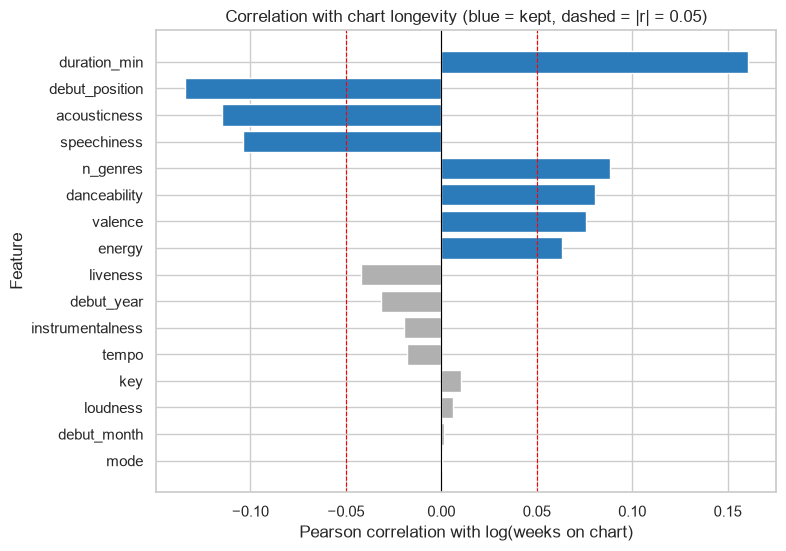

In [32]:
fig, ax = plt.subplots(figsize=(8, 6))
colors = corr_tbl["keep"].map({True: "#2b7bba", False: "#b0b0b0"})
ax.barh(corr_tbl["feature"], corr_tbl["pearson_r"], color=colors)
ax.invert_yaxis()
ax.axvline(0, color="black", lw=0.8)
ax.axvline(0.05, color="red", ls="--", lw=0.8)
ax.axvline(-0.05, color="red", ls="--", lw=0.8)
ax.set_xlabel("Pearson correlation with log(weeks on chart)")
ax.set_ylabel("Feature")
ax.set_title("Correlation with chart longevity (blue = kept, dashed = |r| = 0.05)")
plt.show()

### Step 3 – Two-group comparisons (Welch's t-test)

- **H₀:** mean `log_weeks` is the same in both groups.
- **H₁:** the means differ.

**Mann–Whitney U** is added as a rank-based back-up that does not assume normality; the two tests should agree.

In [33]:
def welch(df, flag):
    g1 = df.loc[df[flag] == 1, "log_weeks"]
    g0 = df.loc[df[flag] == 0, "log_weeks"]
    t, p = stats.ttest_ind(g1, g0, equal_var=False)
    p_mw = stats.mannwhitneyu(g1, g0, alternative="two-sided").pvalue   # rank-based back-up, no normality needed
    pooled = np.sqrt((g1.var() + g0.var()) / 2)
    return {"feature": flag, "n_yes": len(g1), "n_no": len(g0), "mean_yes": g1.mean(),
            "mean_no": g0.mean(), "t": t, "p_value": p, "p_mannwhitney": p_mw,
            "cohens_d": (g1.mean() - g0.mean()) / pooled}

model_df["is_collab_int"] = model_df["is_collab"].astype(int)
two_group = pd.DataFrame([welch(model_df, "explicit"), welch(model_df, "is_collab_int")])
two_group["p_holm"] = multipletests(two_group["p_value"], method="holm")[1]
two_group.round(4)

,feature,n_yes,n_no,mean_yes,mean_no,t,p_value,p_mannwhitney,cohens_d,p_holm
0,explicit,2872,21346,1.7909,2.1714,-15.5989,0.0000,0.0,-0.3495,0.0000
1,is_collab_int,2144,22074,2.1015,2.1287,-1.0487,0.2944,0.0,-0.0260,0.2944


### Step 4 – Several groups (one-way ANOVA and Kruskal–Wallis)

- **H₀:** mean `log_weeks` is equal in every genre family (or decade).
- **H₁:** at least one group mean differs.

Effect size: η² (eta squared) = share of the variance explained by the grouping.

In [34]:
def anova_row(df, group):
    groups = [g["log_weeks"].values for _, g in df.groupby(group) if len(g) >= 20]
    f, p = stats.f_oneway(*groups)
    h, p_kw = stats.kruskal(*groups)
    grand = df["log_weeks"].mean()
    ss_between = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
    ss_total = ((df["log_weeks"] - grand) ** 2).sum()
    return {"feature": group, "groups": len(groups), "F": f, "p_anova": p, "H": h,
            "p_kruskal": p_kw, "eta_squared": ss_between / ss_total}

multi = pd.DataFrame([anova_row(model_df, "genre_main"), anova_row(model_df, "debut_decade")])
multi["p_holm"] = multipletests(multi["p_anova"], method="holm")[1]
multi["keep"] = (multi["p_holm"] < 0.05) & (multi["eta_squared"] >= 0.01)
multi.round(4)

,feature,groups,F,p_anova,H,p_kruskal,eta_squared,p_holm,keep
0,genre_main,8,116.2387,0.0,627.8643,0.0,0.0325,0.0,True
1,debut_decade,8,507.7398,0.0,3066.1332,0.0,0.1280,0.0,True


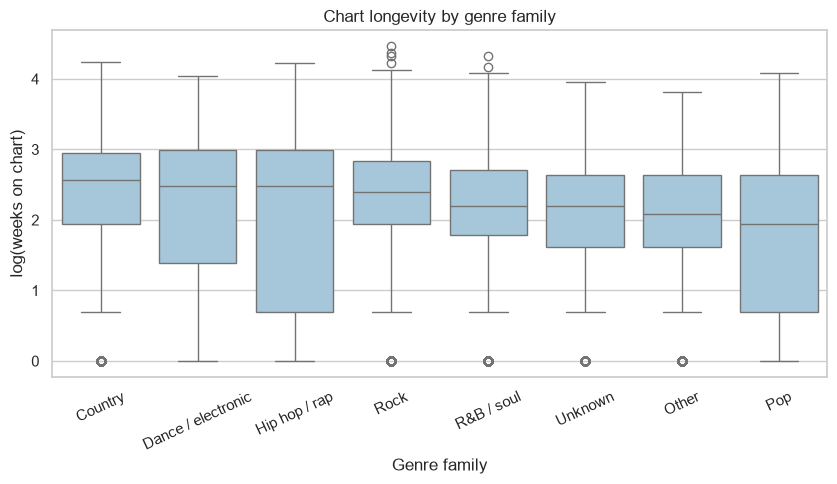

In [35]:
fig, ax = plt.subplots(figsize=(10, 4.5))
order = model_df.groupby("genre_main")["log_weeks"].median().sort_values(ascending=False).index
sns.boxplot(data=model_df, x="genre_main", y="log_weeks", order=order, ax=ax, color="#9ecae1")
ax.set_xlabel("Genre family")
ax.set_ylabel("log(weeks on chart)")
ax.set_title("Chart longevity by genre family")
plt.xticks(rotation=25)
plt.show()

### Step 5 – Decision: which features go into the regression?

In [36]:
selected_numeric = corr_tbl.loc[corr_tbl["keep"], "feature"].tolist()
selected_flags = two_group.loc[(two_group["p_holm"] < 0.05) & (two_group["cohens_d"].abs() >= 0.1), "feature"].tolist()
selected_groups = multi.loc[multi["keep"], "feature"].tolist()

print("Numeric features kept:", selected_numeric)
print("Flags kept:           ", selected_flags)
print("Group variables kept: ", selected_groups)

Numeric features kept: ['duration_min', 'debut_position', 'acousticness', 'speechiness', 'n_genres', 'danceability', 'valence', 'energy']
Flags kept:            ['explicit']
Group variables kept:  ['genre_main', 'debut_decade']


**Reading the tests**

- **Numeric features:** the strongest relationships with chart longevity are `duration_min` (r = +0.16, longer songs stay longer), `debut_position` (r = −0.13, songs that enter higher stay longer), `acousticness` (−0.12), `speechiness` (−0.10), `danceability` (+0.08), `valence` (+0.08) and `energy` (+0.06). `loudness`, `key`, `mode` and `debut_month` have no detectable relationship, and `liveness`, `tempo`, `instrumentalness` and `debut_year` were dropped because their linear effect is below |r| = 0.05.
- **Explicit songs** have a clearly lower mean `log_weeks` (1.79 vs 2.17, Cohen's d = −0.35), and Mann–Whitney U agrees, so `explicit` is kept.
- **Guest-artist songs** (`is_collab`): Welch's test finds no difference in means (p = 0.29) and the effect size is negligible (d = −0.03), so the flag is dropped. Mann–Whitney U does report a difference (p < 0.001), because the *medians* are slightly higher for guest-artist songs while the *means* are slightly lower. With such a small effect the flag adds nothing practical to the model.
- **Genre family** (η² = 0.03) and **debut decade** (η² = 0.13) both differ significantly. The decade effect is not linear in the year (r = −0.03 for the numeric year, but Spearman ρ = +0.13 and η² = 0.13), which is why the decade enters the regression as dummy variables rather than as a number.
- The Kruskal–Wallis tests agree with the ANOVA results.

**Caution:** the p-values are tiny because there are more than 24,000 songs. They show that effects are *real*, not that they are *large*. This is why the effect-size rule is used as well.

## **Linear Regression**

Two models predict `log_weeks`:

- **Model A – all candidate features** (every numeric feature, the two flags and genre family).
- **Model B – tested features only** (the features kept in Step 5).

Both use the same 80/20 train/test split. A collinearity check (VIF) comes first, because audio features such as `energy`, `loudness` and `acousticness` move together.

In [37]:
def design(df, numeric, flags, groups):
    X = df[numeric].copy()
    for f in flags:
        X[f] = df[f]
    for g in groups:
        X = X.join(pd.get_dummies(df[g], prefix=g, drop_first=True, dtype=float))
    return X.astype(float)

all_numeric = numeric_features
X_all = design(model_df, all_numeric, ["explicit", "is_collab_int"], ["genre_main"])
y = model_df["log_weeks"]

vif = pd.DataFrame({"feature": X_all.columns,
                    "VIF": [variance_inflation_factor(sm.add_constant(X_all).values, i + 1)
                            for i in range(X_all.shape[1])]}).sort_values("VIF", ascending=False)
vif.head(8).round(2)

,feature,VIF
5,energy,3.47
19,genre_main_Hip hop / rap,3.41
1,debut_year,2.98
6,loudness,2.70
23,genre_main_Rock,2.50
22,genre_main_R&B / soul,2.30
16,explicit,2.25
11,valence,2.12


In [38]:
sel_numeric = selected_numeric
sel_flags = selected_flags
sel_groups = selected_groups   # genre_main and debut_decade enter as dummy variables
X_sel = design(model_df, sel_numeric, sel_flags, sel_groups)

train_idx, test_idx = train_test_split(model_df.index, test_size=0.2, random_state=RANDOM_STATE)

def fit_eval(X, name):
    ols = sm.OLS(y.loc[train_idx], sm.add_constant(X.loc[train_idx])).fit()
    pred = ols.predict(sm.add_constant(X.loc[test_idx]))
    lr = LinearRegression().fit(X.loc[train_idx], y.loc[train_idx])   # same model in scikit-learn, as a cross-check
    return ols, {"model": name, "n_features": X.shape[1],
                 "R2_train": ols.rsquared, "adj_R2_train": ols.rsquared_adj,
                 "R2_test": r2_score(y.loc[test_idx], pred),
                 "RMSE_test (log weeks)": np.sqrt(mean_squared_error(y.loc[test_idx], pred)),
                 "sklearn_R2_test": lr.score(X.loc[test_idx], y.loc[test_idx])}

ols_all, res_all = fit_eval(X_all, "A: all candidates")
ols_sel, res_sel = fit_eval(X_sel, "B: tested features")
pd.DataFrame([res_all, res_sel]).round(4)

,model,n_features,R2_train,adj_R2_train,R2_test,RMSE_test (log weeks),sklearn_R2_test
0,A: all candidates,25,0.1222,0.1211,0.1242,0.8727,0.1242
1,B: tested features,23,0.1877,0.1867,0.1856,0.8416,0.1856


In [39]:
coef = pd.DataFrame({"coef": ols_sel.params, "p_value": ols_sel.pvalues,
                     "ci_low": ols_sel.conf_int()[0], "ci_high": ols_sel.conf_int()[1]})
coef.round(4)

,coef,p_value,ci_low,ci_high
const,2.8202,0.0000,2.6806,2.9597
duration_min,0.0369,0.0000,0.0235,0.0503
debut_position,-0.0093,0.0000,-0.0099,-0.0086
acousticness,-0.1373,0.0000,-0.1972,-0.0773
speechiness,-0.6827,0.0000,-0.8651,-0.5003
n_genres,0.0039,0.1104,-0.0009,0.0087
danceability,0.4025,0.0000,0.2992,0.5059
valence,0.0985,0.0067,0.0273,0.1697
energy,-0.1096,0.0104,-0.1934,-0.0258
explicit,-0.1836,0.0000,-0.2392,-0.1280


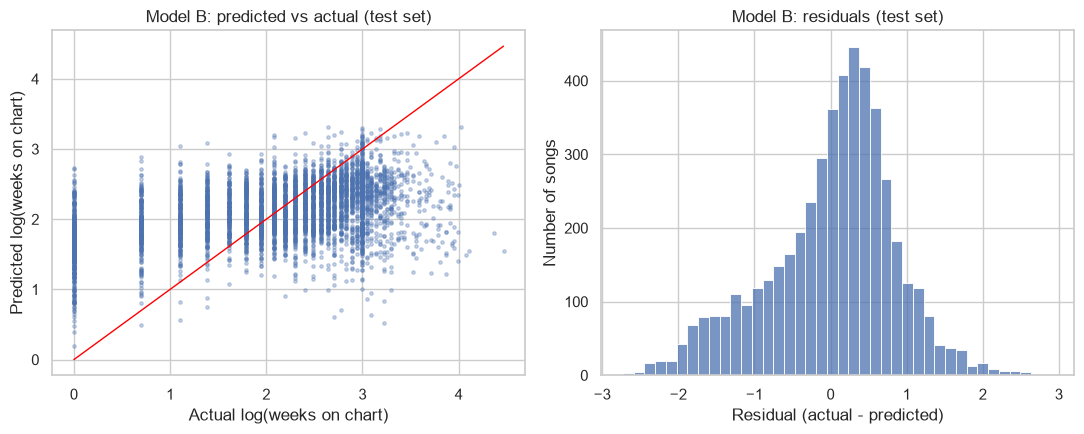

In [40]:
pred_test = ols_sel.predict(sm.add_constant(X_sel.loc[test_idx]))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(y.loc[test_idx], pred_test, s=6, alpha=0.3)
lims = [y.min(), y.max()]
axes[0].plot(lims, lims, color="red", lw=1)
axes[0].set(xlabel="Actual log(weeks on chart)", ylabel="Predicted log(weeks on chart)",
            title="Model B: predicted vs actual (test set)")
resid = y.loc[test_idx] - pred_test
sns.histplot(resid, bins=40, ax=axes[1])
axes[1].set(xlabel="Residual (actual - predicted)", ylabel="Number of songs",
            title="Model B: residuals (test set)")
plt.tight_layout()
plt.show()

### Sensitivity check – do the outliers drive the result?

The chart outliers (very long runs) are real hits, so they stay in the main model. As a check, Model B is refitted **without** the songs flagged by the IQR rule on `weeks_on_chart` or `duration_min`, and the results are compared.

In [41]:
trim_mask = iqr_mask["weeks_on_chart"] | iqr_mask["duration_min"]      # indexed like model_df
keep = ~trim_mask
tr = [i for i in train_idx if keep.loc[i]]
te = [i for i in test_idx if keep.loc[i]]

ols_trim = sm.OLS(y.loc[tr], sm.add_constant(X_sel.loc[tr])).fit()
pred_trim = ols_trim.predict(sm.add_constant(X_sel.loc[te]))

sens = pd.DataFrame({
    "coef (all songs)": ols_sel.params,
    "coef (outliers removed)": ols_trim.params,
    "p (all songs)": ols_sel.pvalues,
    "p (outliers removed)": ols_trim.pvalues,
})
sens["same sign"] = np.sign(sens["coef (all songs)"]) == np.sign(sens["coef (outliers removed)"])
print(f"Songs removed: {int(trim_mask.sum()):,} of {len(model_df):,} ({trim_mask.mean():.1%})")
print(f"R2 test  - all songs: {res_sel['R2_test']:.3f} | outliers removed: {r2_score(y.loc[te], pred_trim):.3f}")
print(f"RMSE test - all songs: {res_sel['RMSE_test (log weeks)']:.3f} | outliers removed: "
      f"{np.sqrt(mean_squared_error(y.loc[te], pred_trim)):.3f}")
print("Coefficients with the same sign in both fits:", int(sens.drop(index="const")["same sign"].sum()), "of", len(sens) - 1, "(excluding the constant)")
sens.drop(index="const").round(4)

Songs removed: 934 of 24,218 (3.9%)
R2 test  - all songs: 0.186 | outliers removed: 0.201
RMSE test - all songs: 0.842 | outliers removed: 0.818
Coefficients with the same sign in both fits: 23 of 23 (excluding the constant)


,coef (all songs),coef (outliers removed),p (all songs),p (outliers removed),same sign
duration_min,0.0369,0.0698,0.0000,0.0000,True
debut_position,-0.0093,-0.0091,0.0000,0.0000,True
acousticness,-0.1373,-0.1409,0.0000,0.0000,True
speechiness,-0.6827,-0.6673,0.0000,0.0000,True
n_genres,0.0039,0.0047,0.1104,0.0549,True
danceability,0.4025,0.3490,0.0000,0.0000,True
valence,0.0985,0.1078,0.0067,0.0031,True
energy,-0.1096,-0.0835,0.0104,0.0510,True
explicit,-0.1836,-0.1596,0.0000,0.0000,True
genre_main_Dance / electronic,-0.3136,-0.3292,0.0000,0.0000,True


**Result.** Removing the 934 songs (3.9 %) flagged on `weeks_on_chart` or `duration_min` leaves the conclusions the same. All coefficients keep their sign, the test R² rises a little (0.186 → 0.201) and the error falls (RMSE 0.842 → 0.818), which is expected because the hardest-to-predict songs were removed. The main effects (speechiness, danceability, explicit, genre family, decade) change by only a few hundredths. The conclusion does not depend on the outliers, so the outliers stay in the final model.

### Leak-safe modelling with a scikit-learn `Pipeline`

The statsmodels fit above is useful for coefficients and p-values. For judging **prediction quality** the preprocessing is packaged with the model in a `Pipeline`, so that scaling and encoding are learned from the training rows only and then applied unchanged to the test rows. Three models are compared on the same split:

- a **baseline** that always predicts the training mean (R² ≈ 0 by construction);
- **Model A** with all candidate features;
- **Model B** with the tested features.

A 5-fold cross-validation then checks that the result does not depend on one lucky split.

In [42]:
def build_pipeline(numeric, flags, categories, regressor):
    """Scale numeric columns, one-hot encode categories, then fit the regressor."""
    prep = ColumnTransformer([
        ("num", StandardScaler(), numeric + flags),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categories),
    ])
    return Pipeline([("prep", prep), ("model", regressor)])

def raw_frame(numeric, flags, categories):
    frame = model_df[numeric + flags + categories].copy()
    for col in categories:
        frame[col] = frame[col].astype(str)          # decade becomes a category, not a number
    return frame

features_A = (all_numeric, ["explicit", "is_collab_int"], ["genre_main"])
features_B = (sel_numeric, sel_flags, sel_groups)
X_A, X_B = raw_frame(*features_A), raw_frame(*features_B)

models = {
    "Baseline (training mean)": (X_B, DummyRegressor(strategy="mean"), features_B),
    "A: all candidates":        (X_A, LinearRegression(), features_A),
    "B: tested features":       (X_B, LinearRegression(), features_B),
}
rows, fitted = [], {}
for name, (X_raw, reg, feats) in models.items():
    pipe = build_pipeline(*feats, reg).fit(X_raw.loc[train_idx], y.loc[train_idx])
    pred = pipe.predict(X_raw.loc[test_idx])
    fitted[name] = pipe
    rows.append({"model": name, "MAE": mean_absolute_error(y.loc[test_idx], pred),
                 "RMSE": np.sqrt(mean_squared_error(y.loc[test_idx], pred)),
                 "R2": r2_score(y.loc[test_idx], pred)})
pipe_results = pd.DataFrame(rows).set_index("model")
pipe_results.round(3)

,MAE,RMSE,R2
model,,,
Baseline (training mean),0.742,0.933,-0.000
A: all candidates,0.689,0.873,0.124
B: tested features,0.655,0.842,0.186


In [43]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, (X_raw, reg, feats) in models.items():
    out = cross_validate(build_pipeline(*feats, reg), X_raw, y, cv=cv,
                         scoring=("r2", "neg_mean_absolute_error"))
    cv_rows.append({"model": name, "R2 mean": out["test_r2"].mean(), "R2 std": out["test_r2"].std(),
                    "MAE mean": -out["test_neg_mean_absolute_error"].mean()})
pd.DataFrame(cv_rows).set_index("model").round(3)

,R2 mean,R2 std,MAE mean
model,,,
Baseline (training mean),-0.000,0.000,0.746
A: all candidates,0.120,0.006,0.696
B: tested features,0.185,0.004,0.661


**Reading the pipeline results**

| Model | Test MAE | Test RMSE | Test R² | 5-fold CV R² (mean ± SD) |
|---|---|---|---|---|
| Baseline (training mean) | 0.742 | 0.933 | 0.000 | 0.000 ± 0.000 |
| A: all candidates | 0.689 | 0.873 | 0.124 | 0.120 ± 0.006 |
| B: tested features | 0.655 | 0.842 | 0.186 | 0.185 ± 0.004 |

- Both regression models beat the baseline, and Model B beats Model A on the test set and in all five folds (the standard deviation is small), so the advantage is not a lucky split.
- The pipeline reproduces the statsmodels result (test R² 0.186), which confirms that both implementations agree.
- A typical prediction is off by about 0.66 in log-weeks (roughly a factor of 1.9 in weeks). That is a meaningful improvement over the baseline, but still large.

**Reading the regression**

| | Model A (all candidates) | Model B (tested features) |
|---|---|---|
| Features | 25 | 23 |
| R² on the test set | 0.124 | 0.186 |
| RMSE on the test set (log weeks) | 0.873 | 0.842 |

- Model B has fewer numeric features but **performs better on unseen songs**: the decade dummies capture the non-linear time effect that the single year column in Model A misses. Dropping features that fail the tests did not hurt.
- **Even the better model explains only about 19 % of the variation.** Characteristics known at debut (sound, length, genre, era, starting rank) are weak predictors of how long a song lasts; popularity, promotion and listener behaviour are not in the data.
- With the log target, a coefficient of 0.1 means about 10 % more weeks. Examples (baseline: Country songs, 1950s): `explicit` ≈ −0.18 (about 17 % fewer weeks), `speechiness` ≈ −0.68, `danceability` ≈ +0.40. Pop is the genre family with the shortest stay (−0.55) and the 1990s have the longest (+0.37).
- `n_genres` is not significant inside the model (p = 0.11) even though it passed the correlation test, because it overlaps with the genre family. It could be dropped in a further iteration.
- The residuals are roughly bell-shaped but the predicted values are squeezed into a narrow band (the model cannot predict very short or very long chart runs well).
- VIF values stay below 3.5, so collinearity among the audio features is not a problem.
- Limitation: only songs with Spotify data (24,218 of 29,389) are used, and the songs without data are older (median debut 1975 vs 1985), so the result mostly describes the more recent chart.

---
# **Answer to the Research Question**

**Short answer:** a little. Characteristics known at debut explain only about **19 % of the variation** in chart longevity on unseen songs (test R² = 0.186, cross-validated R² = 0.185 ± 0.004, against 0 for the baseline). They are statistically real but practically modest.

| Factor | Direction (effect on weeks on chart) |
|---|---|
| Longer song duration | more weeks |
| Higher debut rank (smaller number) | more weeks |
| Danceability and valence | more weeks |
| Speechiness, acousticness and energy | fewer weeks |
| Explicit lyrics | fewer weeks (about 17 % fewer, other factors equal) |
| Genre family | Country stays longest, Pop shortest |
| Debut decade | 1980s–2000s stay longer than the 1950s–1970s |
| Guest artist, key, mode, tempo, release month | no useful effect |

**How we got here**

1. Loaded and inspected the chart and audio files, and checked duplicates (Tasks 2.1 and 2.5).
2. Built a wide table, reshaped it with `melt()`, cleaned the week labels with string methods, and handled missing ranks, impossible values and missing audio features (Tasks 2.2–2.5).
3. Rebuilt the chart dates and checked them against the real ones (Task 2.6).
4. Created one row per song with features known at debut and kept leaking variables (`peak_position`, `n_instances`, Spotify popularity) out of the model.
5. Compared outlier rules (box plot, IQR, Z-score); kept the long-running hits because they are real, and showed the model does not depend on them.
6. Used correlation tests, Welch t-tests with Mann–Whitney back-ups, and ANOVA (with a Holm correction and effect-size rules) to choose the features.
7. Compared a model with all features against one with the tested features in a leak-safe pipeline with cross-validation: the tested model generalised better.
